In [4]:
import pandas as pd

weather_data = pd.read_csv("merged_complete_datasets/df_weather_combined_all_updated.csv")

In [8]:
# Check the dataset dimensions
print("Dataset shape:",weather_data.shape)

# Inspect column names and data types
print("\nColumn information:")
weather_data.info()

# Display the first five rows
print("\nFirst five rows:")
display(weather_data.head())

# Display basic descriptive statistics
print("\nDescriptive statistics:")
display(weather_data.describe(include="all").T)

Dataset shape: (4265, 14)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 4265 entries, 0 to 4264
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      4265 non-null   int64  
 1   station_id      2750 non-null   float64
 2   date            4265 non-null   str    
 3   tavg            4250 non-null   float64
 4   tmin            4249 non-null   float64
 5   tmax            4249 non-null   float64
 6   prcp            4249 non-null   float64
 7   wspd            2591 non-null   float64
 8   tsun            1762 non-null   float64
 9   cloud_cover     1630 non-null   float64
 10  pres_dwd        1635 non-null   float64
 11  station         4265 non-null   str    
 12  source          4265 non-null   str    
 13  pres_meteostat  1505 non-null   float64
dtypes: float64(10), int64(1), str(3)
memory usage: 602.9 KB

First five rows:


,Unnamed: 0,station_id,date,tavg,tmin,tmax,prcp,wspd,tsun,cloud_cover,pres_dwd,station,source,pres_meteostat
0,0,427.0,2025-04-09 00:00:00,8.9,1.8,15.4,0.0,12.96,NaN,NaN,1015.8,Berlin Brandenburg,DWD,NaN
1,1,427.0,2025-04-10 00:00:00,9.1,5.1,14.0,0.0,19.08,NaN,5.3,1016.4,Berlin Brandenburg,DWD,NaN
2,2,427.0,2025-04-11 00:00:00,9.7,4.9,14.8,0.0,21.60,NaN,7.2,1009.7,Berlin Brandenburg,DWD,NaN
3,3,427.0,2025-04-12 00:00:00,11.1,4.3,17.4,0.0,7.92,NaN,4.5,1007.9,Berlin Brandenburg,DWD,NaN
4,4,427.0,2025-04-13 00:00:00,14.8,6.8,22.8,0.0,15.12,NaN,4.5,1000.6,Berlin Brandenburg,DWD,NaN



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,4265.0,NaN,NaN,NaN,2132.0,1231.343778,0.0,1066.0,2132.0,3198.0,4264.0
station_id,2750.0,NaN,NaN,NaN,416.6,13.034638,400.0,403.0,420.0,427.0,433.0
date,4265,570,2026-01-01 00:00:00,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tavg,4250.0,NaN,NaN,NaN,12.336282,7.822922,-9.1,7.625,13.65,18.1,31.7
tmin,4249.0,NaN,NaN,NaN,7.389739,6.897631,-14.1,2.5,8.4,12.8,23.8
tmax,4249.0,NaN,NaN,NaN,17.240668,9.188478,-7.3,12.0,18.8,23.7,40.3
prcp,4249.0,NaN,NaN,NaN,1.310026,3.43584,0.0,0.0,0.0,0.9,54.5
wspd,2591.0,NaN,NaN,NaN,12.841281,4.455085,3.6,9.5,12.24,15.48,34.2
tsun,1762.0,NaN,NaN,NaN,373.615834,266.571129,0.0,122.25,372.0,576.0,966.0
cloud_cover,1630.0,NaN,NaN,NaN,5.160491,2.265794,0.0,3.5,5.65,7.1,8.0


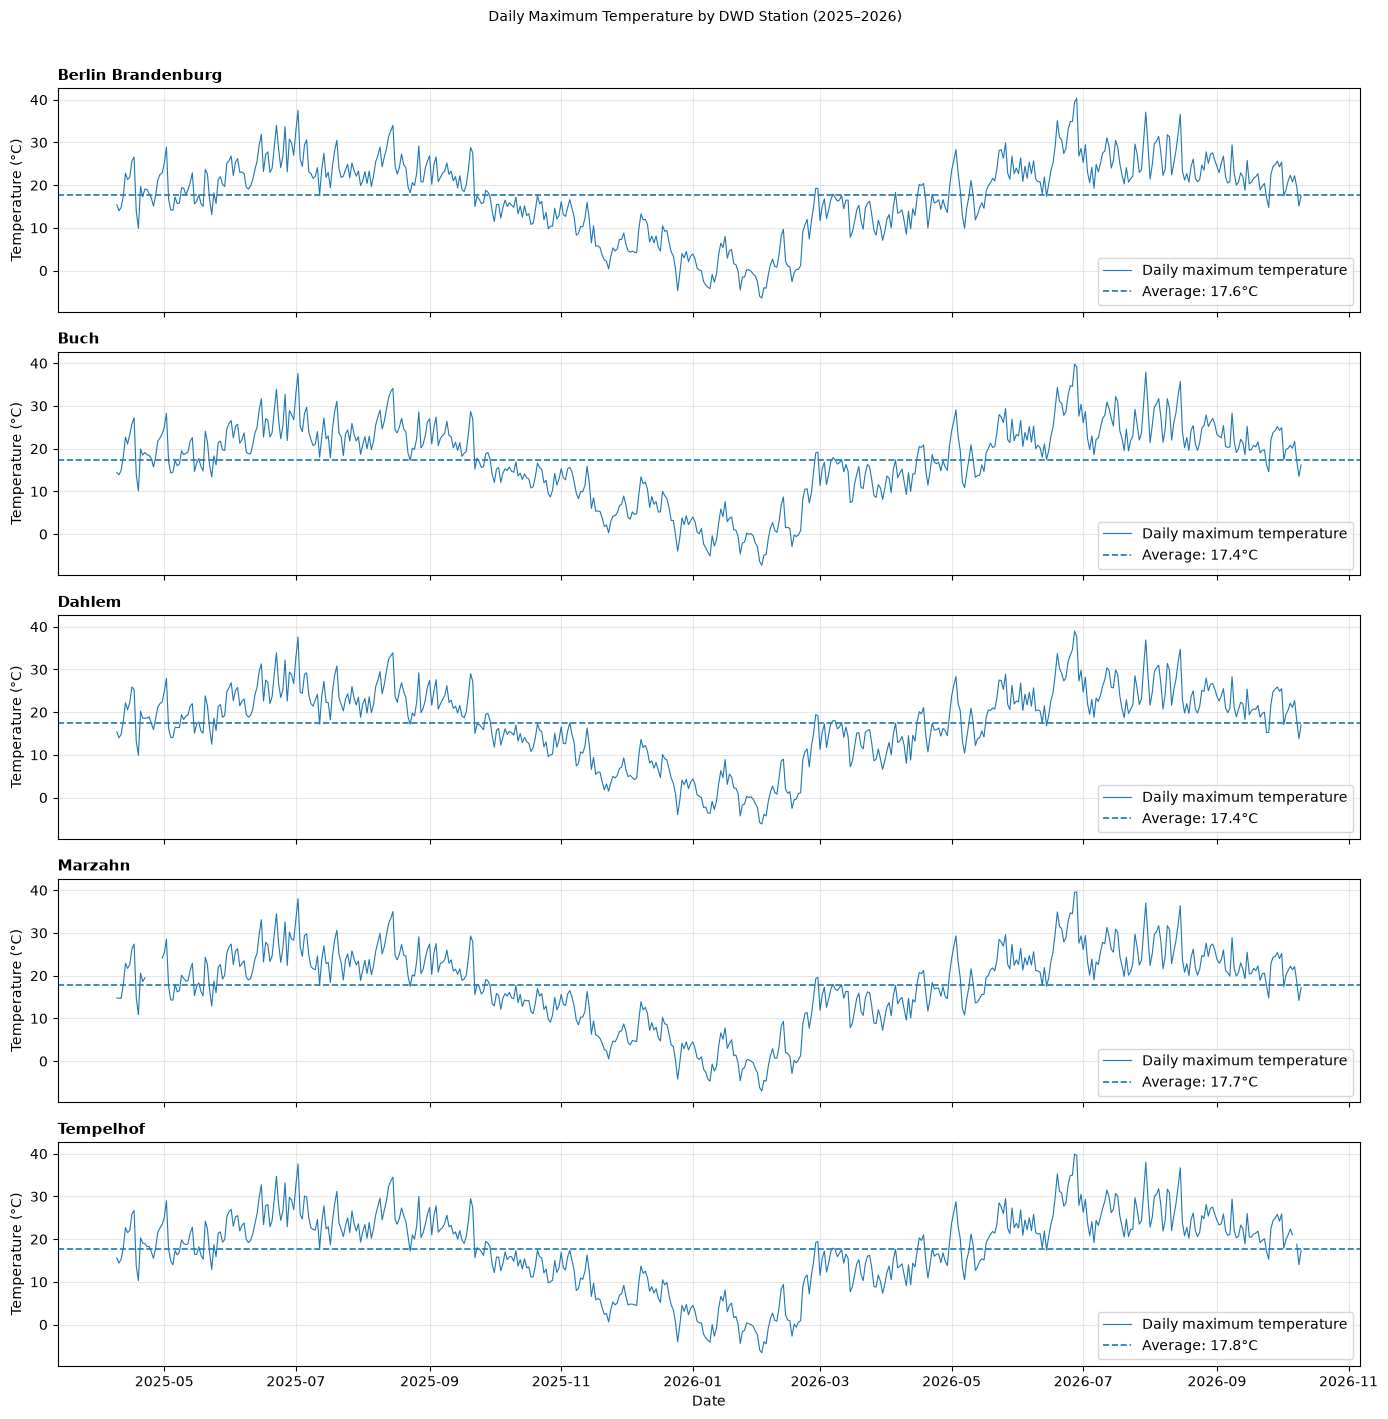

In [47]:
import matplotlib.pyplot as plt

# Keep DWD records only
weather_dwd = weather_data[
    weather_data["source"] == "DWD"
].copy()

# Create a table with dates as rows and stations as columns
temperature_trend = weather_dwd.pivot(
    index="date",
    columns="station",
    values="tmax"
)

# Create one graph per station
fig, axes = plt.subplots(
    nrows=len(temperature_trend.columns),
    ncols=1,
    figsize=(14, 14),
    sharex=True,
    sharey=True
)

# Plot temperature and average for each station
for ax, station in zip(axes, temperature_trend.columns):

    station_data = temperature_trend[station]
    avg_temp = station_data.mean()

    # Plot daily maximum temperature
    ax.plot(
        station_data.index,
        station_data,
        linewidth=0.8,
        label="Daily maximum temperature"
    )

    # Add average temperature line
    ax.axhline(
        avg_temp,
        linestyle="--",
        linewidth=1.2,
        label=f"Average: {avg_temp:.1f}°C"
    )

    # Add station name and formatting
    ax.set_title(station, loc="left", fontsize=11, fontweight="bold")
    ax.set_ylabel("Temperature (°C)")
    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.3)

# Add overall chart title
fig.suptitle(
    "Daily Maximum Temperature by DWD Station (2025–2026)",
    fontsize=10,
    y=1.01
)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

- Every station shows similar trends: peak temperatures from June to September, lowering from October with lowest peack betwen December and March 

In [6]:
# Convert date column to datetime
weather_data["date"] = pd.to_datetime(weather_data["date"])

# Check the data type
print(weather_data["date"].dtype)

datetime64[us]


In [7]:
# Keep DWD records and summer months (June–September)
summer_weather = weather_data[
    (weather_data["source"] == "DWD") &
    (weather_data["date"].dt.month.isin([6, 7, 8, 9]))
].copy()

# Add the year as a separate column
summer_weather["year"] = summer_weather["date"].dt.year

# Find the row with the highest daily maximum temperature per station and year
hottest_days = summer_weather.loc[
    summer_weather.groupby(["station", "year"])["tmax"].idxmax(),
    ["station", "year", "date", "tmax", "tavg", "tmin"]
]

# Sort the results by station and year
hottest_days = hottest_days.sort_values(
    ["station", "year"]
).reset_index(drop=True)

# Display the results
display(hottest_days)

,station,year,date,tmax,tavg,tmin
0,Berlin Brandenburg,2025,2025-07-02,37.5,28.5,15.9
1,Berlin Brandenburg,2026,2026-06-28,40.3,31.6,23.5
2,Buch,2025,2025-07-02,37.6,27.9,16.2
3,Buch,2026,2026-06-27,39.8,30.2,19.0
4,Dahlem,2025,2025-07-02,37.6,27.1,15.1
5,Dahlem,2026,2026-06-27,39.0,28.6,18.6
6,Marzahn,2025,2025-07-02,38.0,29.2,18.5
7,Marzahn,2026,2026-06-28,39.6,31.4,23.7
8,Tempelhof,2025,2025-07-02,37.6,29.2,17.9
9,Tempelhof,2026,2026-06-27,39.9,31.4,22.0


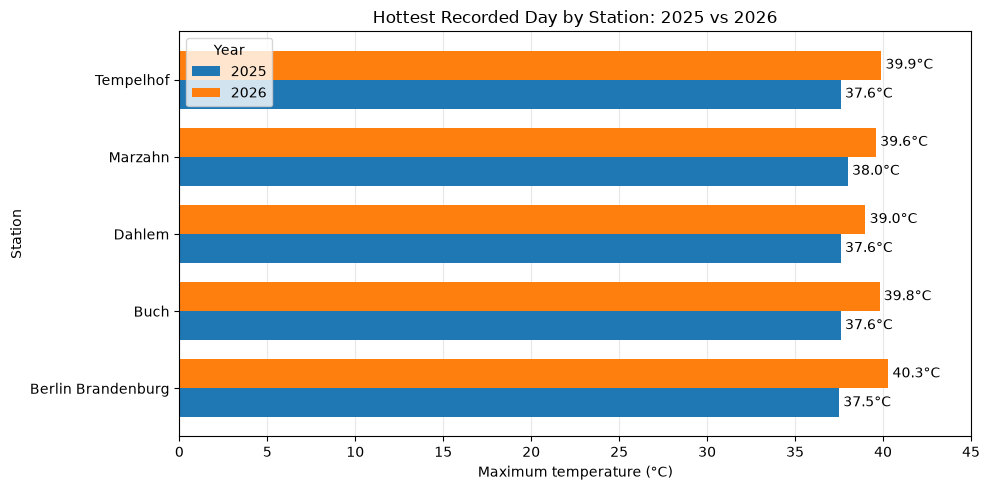

In [17]:
# Arrange the data for plotting
plot_data = hottest_days.pivot(
    index="station",
    columns="year",
    values="tmax"
)

# Create the grouped horizontal bar chart
ax = plot_data.plot(
    kind="barh",
    figsize=(10, 5),
    width=0.75
)

# Add temperature labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f°C", padding=3)

# Format the chart
ax.set_title("Hottest Recorded Day by Station: 2025 vs 2026")
ax.set_xlabel("Maximum temperature (°C)")
ax.set_ylabel("Station")
ax.set_xlim(0, 45)
ax.legend(title="Year")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

- Every station shows an increase in the hottest recorded day from 2025 to 2026
- The increase is around 2-3 degrees

In [18]:
# Keep all DWD stations and only the two additional Meteostat stations
weather_combined = weather_data[
    (weather_data["source"] == "DWD") |
    (
        (weather_data["source"] == "Meteostat") &
        (weather_data["station"].isin(["Alexanderplatz", "Tegel"]))
    )
].copy()

# Extract the year
weather_combined["year"] = weather_combined["date"].dt.year

# Keep 2025 and 2026, excluding missing maximum temperatures
weather_combined = weather_combined[
    weather_combined["year"].isin([2025, 2026]) &
    weather_combined["tmax"].notna()
]

# Find the hottest day for each station and year
hottest_days_all = weather_combined.loc[
    weather_combined.groupby(["station", "year"])["tmax"].idxmax(),
    ["station", "year", "date", "tmax", "tavg", "tmin"]
].sort_values(["station", "year"])

display(hottest_days_all)

,station,year,date,tmax,tavg,tmin
2927,Alexanderplatz,2026,2026-06-27,38.5,29.4,19.5
84,Berlin Brandenburg,2025,2025-07-02,37.5,28.5,15.9
445,Berlin Brandenburg,2026,2026-06-28,40.3,31.6,23.5
634,Buch,2025,2025-07-02,37.6,27.9,16.2
994,Buch,2026,2026-06-27,39.8,30.2,19.0
1184,Dahlem,2025,2025-07-02,37.6,27.1,15.1
1544,Dahlem,2026,2026-06-27,39.0,28.6,18.6
1734,Marzahn,2025,2025-07-02,38.0,29.2,18.5
2095,Marzahn,2026,2026-06-28,39.6,31.4,23.7
3836,Tegel,2026,2026-06-27,38.4,29.2,19.2


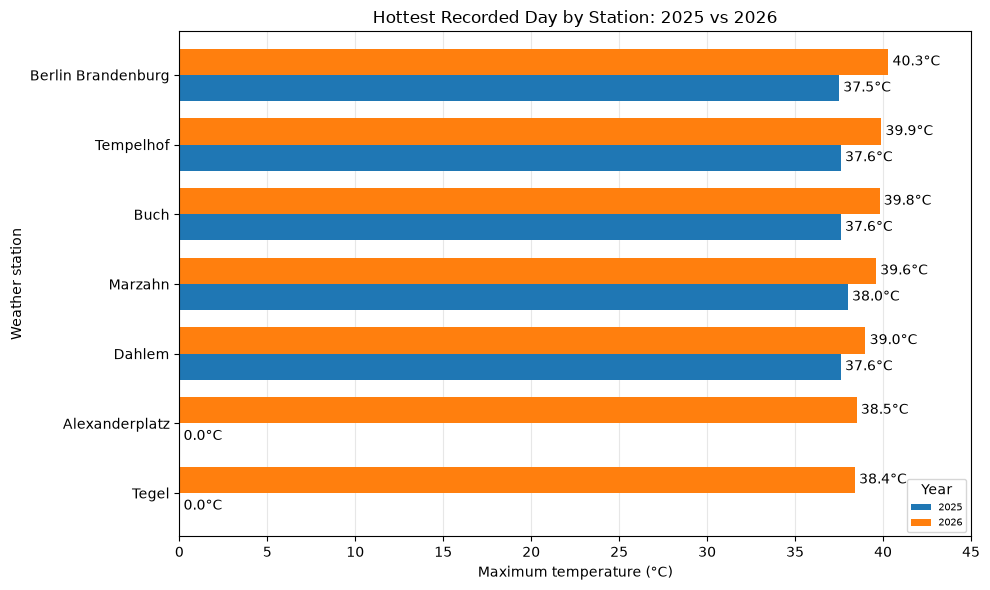

In [28]:
#Adding two more stations for 2026

# Arrange the data for plotting
plot_data = hottest_days_all.pivot(
    index="station",
    columns="year",
    values="tmax"
)

# Sort stations by their 2026 maximum temperature
plot_data = plot_data.sort_values(
    by=2026,
    ascending=True
)

# Create the grouped horizontal bar chart
ax = plot_data.plot(
    kind="barh",
    figsize=(10, 6),
    width=0.75
)

# Add temperature labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f°C", padding=3)

# Format the chart
ax.set_title("Hottest Recorded Day by Station: 2025 vs 2026")
ax.set_xlabel("Maximum temperature (°C)")
ax.set_ylabel("Weather station")
ax.set_xlim(0, 45)
ax.legend(title="Year", fontsize="x-small")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [19]:
# Keep five DWD stations and the two additional Meteostat stations
weather_combined = weather_data[
    (weather_data["source"] == "DWD") |
    (
        (weather_data["source"] == "Meteostat") &
        (weather_data["station"].isin(["Alexanderplatz", "Tegel"]))
    )
].copy()

# Extract year and keep valid temperature observations
weather_combined["year"] = weather_combined["date"].dt.year

weather_combined = weather_combined[
    weather_combined["year"].isin([2025, 2026]) &
    weather_combined["tmax"].notna()
].copy()

# Sort observations chronologically
weather_combined = weather_combined.sort_values(
    ["station", "year", "date"]
)

# Function to find the longest consecutive spell
def longest_hot_spell(group, threshold):

    # Identify days above the temperature threshold
    hot_days = group[group["tmax"] > threshold].copy()

    if hot_days.empty:
        return pd.Series({
            "longest_streak": 0,
            "start_date": pd.NaT,
            "end_date": pd.NaT
        })

    # Start a new streak if dates are not consecutive
    new_streak = hot_days["date"].diff().dt.days.ne(1)

    hot_days["streak_id"] = new_streak.cumsum()

    # Calculate the length of each streak
    streaks = hot_days.groupby("streak_id").agg(
        longest_streak=("date", "size"),
        start_date=("date", "min"),
        end_date=("date", "max")
    )

    # Return the longest streak
    return streaks.sort_values(
        ["longest_streak", "start_date"],
        ascending=[False, True]
    ).iloc[0]

# Calculate longest spells for each station and year
results = []

for (station, year), group in weather_combined.groupby(
    ["station", "year"]
):

    for threshold, label in [(30, "hot"), (35, "very_hot")]:

        result = longest_hot_spell(group, threshold)

        results.append({
            "station": station,
            "year": year,
            "temperature_category": label,
            **result.to_dict()
        })

# Display results
hot_streaks = pd.DataFrame(results)

display(
    hot_streaks.sort_values(
        ["station", "year", "temperature_category"]
    ).reset_index(drop=True)
)

,station,year,temperature_category,longest_streak,start_date,end_date
0,Alexanderplatz,2025,hot,3,2025-08-13,2025-08-15
1,Alexanderplatz,2025,very_hot,1,2025-07-02,2025-07-02
2,Alexanderplatz,2026,hot,5,2026-06-24,2026-06-28
3,Alexanderplatz,2026,very_hot,2,2026-06-27,2026-06-28
4,Berlin Brandenburg,2025,hot,3,2025-08-13,2025-08-15
5,Berlin Brandenburg,2025,very_hot,1,2025-07-02,2025-07-02
6,Berlin Brandenburg,2026,hot,5,2026-06-24,2026-06-28
7,Berlin Brandenburg,2026,very_hot,2,2026-06-27,2026-06-28
8,Buch,2025,hot,3,2025-08-13,2025-08-15
9,Buch,2025,very_hot,1,2025-07-02,2025-07-02


- Hot days are defined with temperatures > 30 C, very hot days with temperatures > 35.
- Longer heat spells in 2026: the longest spell above 30°C increased from three to five consecutive days.
- More persistent extreme heat: the longest spell above 35°C doubled from one to two days.
- Consistent timing across Berlin: all seven stations recorded their longest 2026 hot spell between 24 and 28 June.

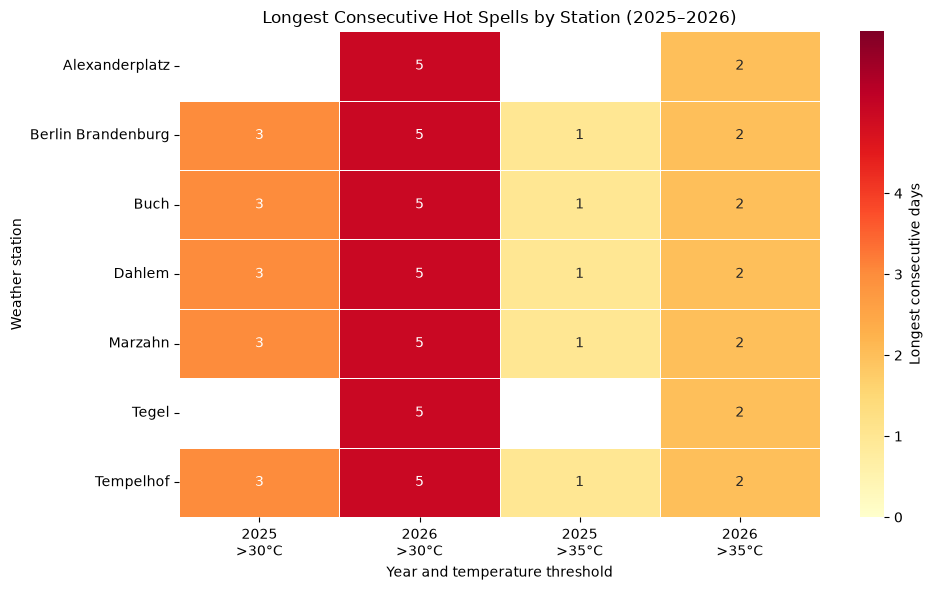

In [39]:
import seaborn as sns

# Create the heatmap table
heatmap_data = hot_streaks.pivot(
    index="station",
    columns=["year", "temperature_category"],
    values="longest_streak"
)

# Set the column order
heatmap_data = heatmap_data.reindex(
    columns=[
        (2025, "hot"),
        (2026, "hot"),
        (2025, "very_hot"),
        (2026, "very_hot")
    ]
)

# Create readable column labels
heatmap_data.columns = [
    "2025\n>30°C",
    "2026\n>30°C",
    "2025\n>35°C",
    "2026\n>35°C"
]

# Create the heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5,
    vmin=0,
    vmax=6,
    cbar_kws={"label": "Longest consecutive days",
                "ticks": range(0,5)
    }
)

# Format the chart
plt.title("Longest Consecutive Hot Spells by Station (2025–2026)")
plt.xlabel("Year and temperature threshold")
plt.ylabel("Weather station")

plt.tight_layout()
plt.show()

In [20]:
# Keep five DWD stations and the two additional Meteostat stations
weather_combined = weather_data[
    (weather_data["source"] == "DWD") |
    (
        (weather_data["source"] == "Meteostat") &
        (weather_data["station"].isin(["Alexanderplatz", "Tegel"]))
    )
].copy()

# Extract year
weather_combined["year"] = weather_combined["date"].dt.year

# Keep 2025 and 2026 with valid maximum temperatures
weather_combined = weather_combined[
    weather_combined["year"].isin([2025, 2026]) &
    weather_combined["tmax"].notna()
].copy()

# Calculate hot-day frequency by station and year
hot_days_summary = weather_combined.groupby(
    ["station", "year"]
).agg(
    observed_days=("tmax", "count"),
    hot_days=("tmax", lambda x: (x > 30).sum()),
    very_hot_days=("tmax", lambda x: (x > 35).sum()),
    avg_tmax=("tmax", "mean")
).reset_index()

# Calculate percentages of observed days
hot_days_summary["hot_days_pct"] = (
    hot_days_summary["hot_days"] /
    hot_days_summary["observed_days"] * 100
).round(2)

hot_days_summary["very_hot_days_pct"] = (
    hot_days_summary["very_hot_days"] /
    hot_days_summary["observed_days"] * 100
).round(2)

# Round average maximum temperature
hot_days_summary["avg_tmax"] = hot_days_summary["avg_tmax"].round(1)

# Display results
display(
    hot_days_summary.sort_values(
        ["station", "year"]
    ).reset_index(drop=True)
)

,station,year,observed_days,hot_days,very_hot_days,avg_tmax,hot_days_pct,very_hot_days_pct
0,Alexanderplatz,2025,365,6,1,14.3,1.64,0.27
1,Alexanderplatz,2026,303,12,3,15.9,3.96,0.99
2,Berlin Brandenburg,2025,267,11,1,18.0,4.12,0.37
3,Berlin Brandenburg,2026,283,18,5,17.3,6.36,1.77
4,Buch,2025,267,9,1,17.8,3.37,0.37
5,Buch,2026,283,20,4,17.1,7.07,1.41
6,Dahlem,2025,267,9,1,17.9,3.37,0.37
7,Dahlem,2026,283,15,3,17.0,5.30,1.06
8,Marzahn,2025,260,10,1,18.1,3.85,0.38
9,Marzahn,2026,283,19,4,17.4,6.71,1.41


every station shows large increase of hot days (some more than double the amount) and very hot days

In [41]:
# Keep observations from June to September
summer_data = weather_combined[
    weather_combined["date"].dt.month.isin([6, 7, 8, 9])
].copy()

# Calculate hot-day frequency by station and year
summer_summary = summer_data.groupby(
    ["station", "year"]
).agg(
    observed_days=("tmax", "count"),
    hot_days=("tmax", lambda x: (x > 30).sum()),
    very_hot_days=("tmax", lambda x: (x > 35).sum()),
    avg_tmax=("tmax", "mean")
).reset_index()

# Calculate percentages
summer_summary["hot_days_pct"] = (
    summer_summary["hot_days"] /
    summer_summary["observed_days"] * 100
).round(2)

summer_summary["very_hot_days_pct"] = (
    summer_summary["very_hot_days"] /
    summer_summary["observed_days"] * 100
).round(2)

# Round average maximum temperature
summer_summary["avg_tmax"] = summer_summary["avg_tmax"].round(1)

# Display results
display(
    summer_summary.sort_values(
        ["station", "year"]
    ).reset_index(drop=True)
)

,station,year,observed_days,hot_days,very_hot_days,avg_tmax,hot_days_pct,very_hot_days_pct
0,Alexanderplatz,2026,122,12,3,23.4,9.84,2.46
1,Berlin Brandenburg,2025,122,11,1,23.9,9.02,0.82
2,Berlin Brandenburg,2026,122,18,5,25.1,14.75,4.10
3,Buch,2025,122,9,1,23.7,7.38,0.82
4,Buch,2026,122,20,4,24.8,16.39,3.28
5,Dahlem,2025,122,9,1,23.8,7.38,0.82
6,Dahlem,2026,122,15,3,24.5,12.30,2.46
7,Marzahn,2025,122,10,1,24.1,8.20,0.82
8,Marzahn,2026,122,19,4,25.1,15.57,3.28
9,Tegel,2026,122,12,3,23.3,9.84,2.46


Key findings:
- More hot days (above 30°C).
- More very hot days (above 35°C).
- Higher average daily maximum temperatures.

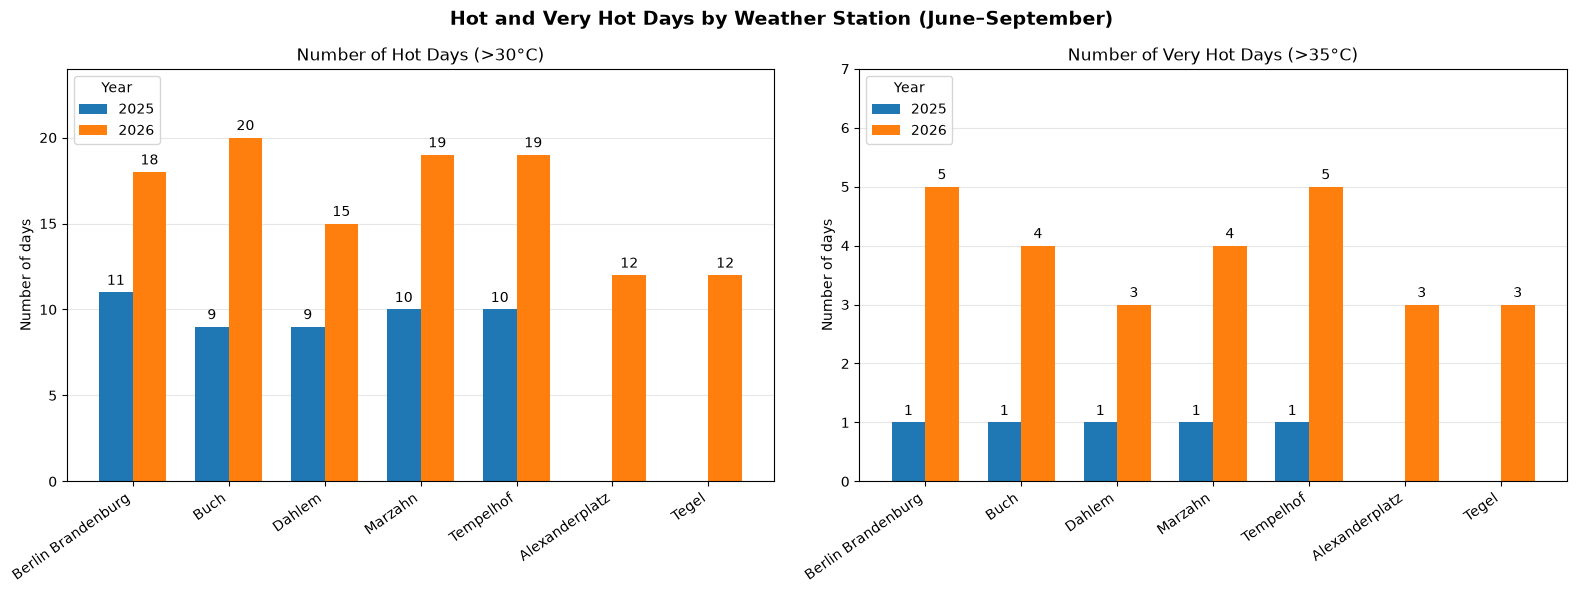

In [42]:
import numpy as np

# Define station order
station_order = [
    "Berlin Brandenburg",
    "Buch",
    "Dahlem",
    "Marzahn",
    "Tempelhof",
    "Alexanderplatz",
    "Tegel"
]

# Prepare data for plotting
plot_data = summer_summary.pivot(
    index="station",
    columns="year",
    values=["hot_days", "very_hot_days"]
).reindex(station_order)

# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Define bar positions
x = np.arange(len(station_order))
width = 0.35

# Plot hot days
for i, year in enumerate([2025, 2026]):
    values = plot_data["hot_days"][year].values
    bars = axes[0].bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=year
    )
    axes[0].bar_label(bars, padding=3, fmt="%.0f")

# Plot very hot days
for i, year in enumerate([2025, 2026]):
    values = plot_data["very_hot_days"][year].values
    bars = axes[1].bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=year
    )
    axes[1].bar_label(bars, padding=3, fmt="%.0f")

# Format first chart
axes[0].set_title("Number of Hot Days (>30°C)")
axes[0].set_ylabel("Number of days")
axes[0].set_xticks(x)
axes[0].set_xticklabels(station_order, rotation=35, ha="right")
axes[0].legend(title="Year")
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_axisbelow(True)
axes[0].set_ylim(0, 24)

# Format second chart
axes[1].set_title("Number of Very Hot Days (>35°C)")
axes[1].set_ylabel("Number of days")
axes[1].set_xticks(x)
axes[1].set_xticklabels(station_order, rotation=35, ha="right")
axes[1].legend(title="Year")
axes[1].grid(axis="y", alpha=0.3)
axes[1].set_axisbelow(True)
axes[1].set_ylim(0, 7)

# Add overall title
fig.suptitle(
    "Hot and Very Hot Days by Weather Station (June–September)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [43]:
# Filter observations from June to September
summer_data = weather_combined[
    weather_combined["date"].dt.month.isin([6, 7, 8, 9])
].copy()

# Calculate tropical nights for each station and year
tropical_results = []

for (station, year), group in summer_data.groupby(["station", "year"]):

    # Keep observations with valid minimum temperatures
    valid_data = group.dropna(subset=["tmin"]).sort_values("date")

    # Identify tropical nights
    tropical_nights = valid_data[
        valid_data["tmin"] >= 20
    ].copy()

    # Count tropical nights
    total_nights = len(tropical_nights)

    # Calculate percentage of observed nights
    tropical_pct = (
        total_nights / len(valid_data) * 100
        if len(valid_data) > 0 else 0
    )

    # Find consecutive tropical-night spells
    tropical_nights["new_streak"] = (
        tropical_nights["date"].diff().dt.days.ne(1)
    )

    tropical_nights["streak_id"] = (
        tropical_nights["new_streak"].cumsum()
    )

    # Identify the longest spell
    if total_nights > 0:
        streaks = tropical_nights.groupby("streak_id").agg(
            streak_length=("date", "size"),
            start_date=("date", "min"),
            end_date=("date", "max")
        )

        longest = streaks.sort_values(
            ["streak_length", "start_date"],
            ascending=[False, True]
        ).iloc[0]

        longest_streak = longest["streak_length"]
        start_date = longest["start_date"]
        end_date = longest["end_date"]

    else:
        longest_streak = 0
        start_date = pd.NaT
        end_date = pd.NaT

    tropical_results.append({
        "station": station,
        "year": year,
        "observed_nights": len(valid_data),
        "tropical_nights": total_nights,
        "tropical_nights_pct": round(tropical_pct, 2),
        "longest_streak": longest_streak,
        "start_date": start_date,
        "end_date": end_date
    })

# Create the results table
tropical_summary = pd.DataFrame(tropical_results)

display(
    tropical_summary.sort_values(
        ["station", "year"]
    ).reset_index(drop=True)
)

,station,year,observed_nights,tropical_nights,tropical_nights_pct,longest_streak,start_date,end_date
0,Alexanderplatz,2026,122,5,4.10,2,2026-06-28,2026-06-29
1,Berlin Brandenburg,2025,122,0,0.00,0,NaT,NaT
2,Berlin Brandenburg,2026,122,1,0.82,1,2026-06-28,2026-06-28
3,Buch,2025,122,0,0.00,0,NaT,NaT
4,Buch,2026,122,1,0.82,1,2026-06-28,2026-06-28
5,Dahlem,2025,122,0,0.00,0,NaT,NaT
6,Dahlem,2026,122,1,0.82,1,2026-06-28,2026-06-28
7,Marzahn,2025,122,0,0.00,0,NaT,NaT
8,Marzahn,2026,122,3,2.46,2,2026-06-27,2026-06-28
9,Tegel,2026,122,4,3.28,2,2026-06-28,2026-06-29


Defining tropical nights as nights with temperature > 20 C. Calculated using minimum temperature recorded on the day

Tropical nights are absent during 2025, appearing in all stations the next year

In [44]:
# Calculate average temperatures by station and year
temperature_summary = summer_data.groupby(
    ["station", "year"]
).agg(
    observed_tmax=("tmax", "count"),
    observed_tavg=("tavg", "count"),
    observed_tmin=("tmin", "count"),
    avg_tmax=("tmax", "mean"),
    avg_tavg=("tavg", "mean"),
    avg_tmin=("tmin", "mean")
).reset_index()

# Round average temperatures
temperature_summary[
    ["avg_tmax", "avg_tavg", "avg_tmin"]
] = temperature_summary[
    ["avg_tmax", "avg_tavg", "avg_tmin"]
].round(1)

# Display results
display(
    temperature_summary.sort_values(
        ["station", "year"]
    ).reset_index(drop=True)
)

,station,year,observed_tmax,observed_tavg,observed_tmin,avg_tmax,avg_tavg,avg_tmin
0,Alexanderplatz,2026,122,122,122,23.4,18.8,14.2
1,Berlin Brandenburg,2025,122,122,122,23.9,18.3,12.4
2,Berlin Brandenburg,2026,122,122,122,25.1,19.1,12.8
3,Buch,2025,122,122,122,23.7,17.8,11.9
4,Buch,2026,122,122,122,24.8,18.5,12.4
5,Dahlem,2025,122,122,122,23.8,18.1,12.6
6,Dahlem,2026,122,122,122,24.5,18.6,13.1
7,Marzahn,2025,122,122,122,24.1,18.7,13.4
8,Marzahn,2026,122,122,122,25.1,19.3,13.9
9,Tegel,2026,122,122,122,23.3,18.6,14.0


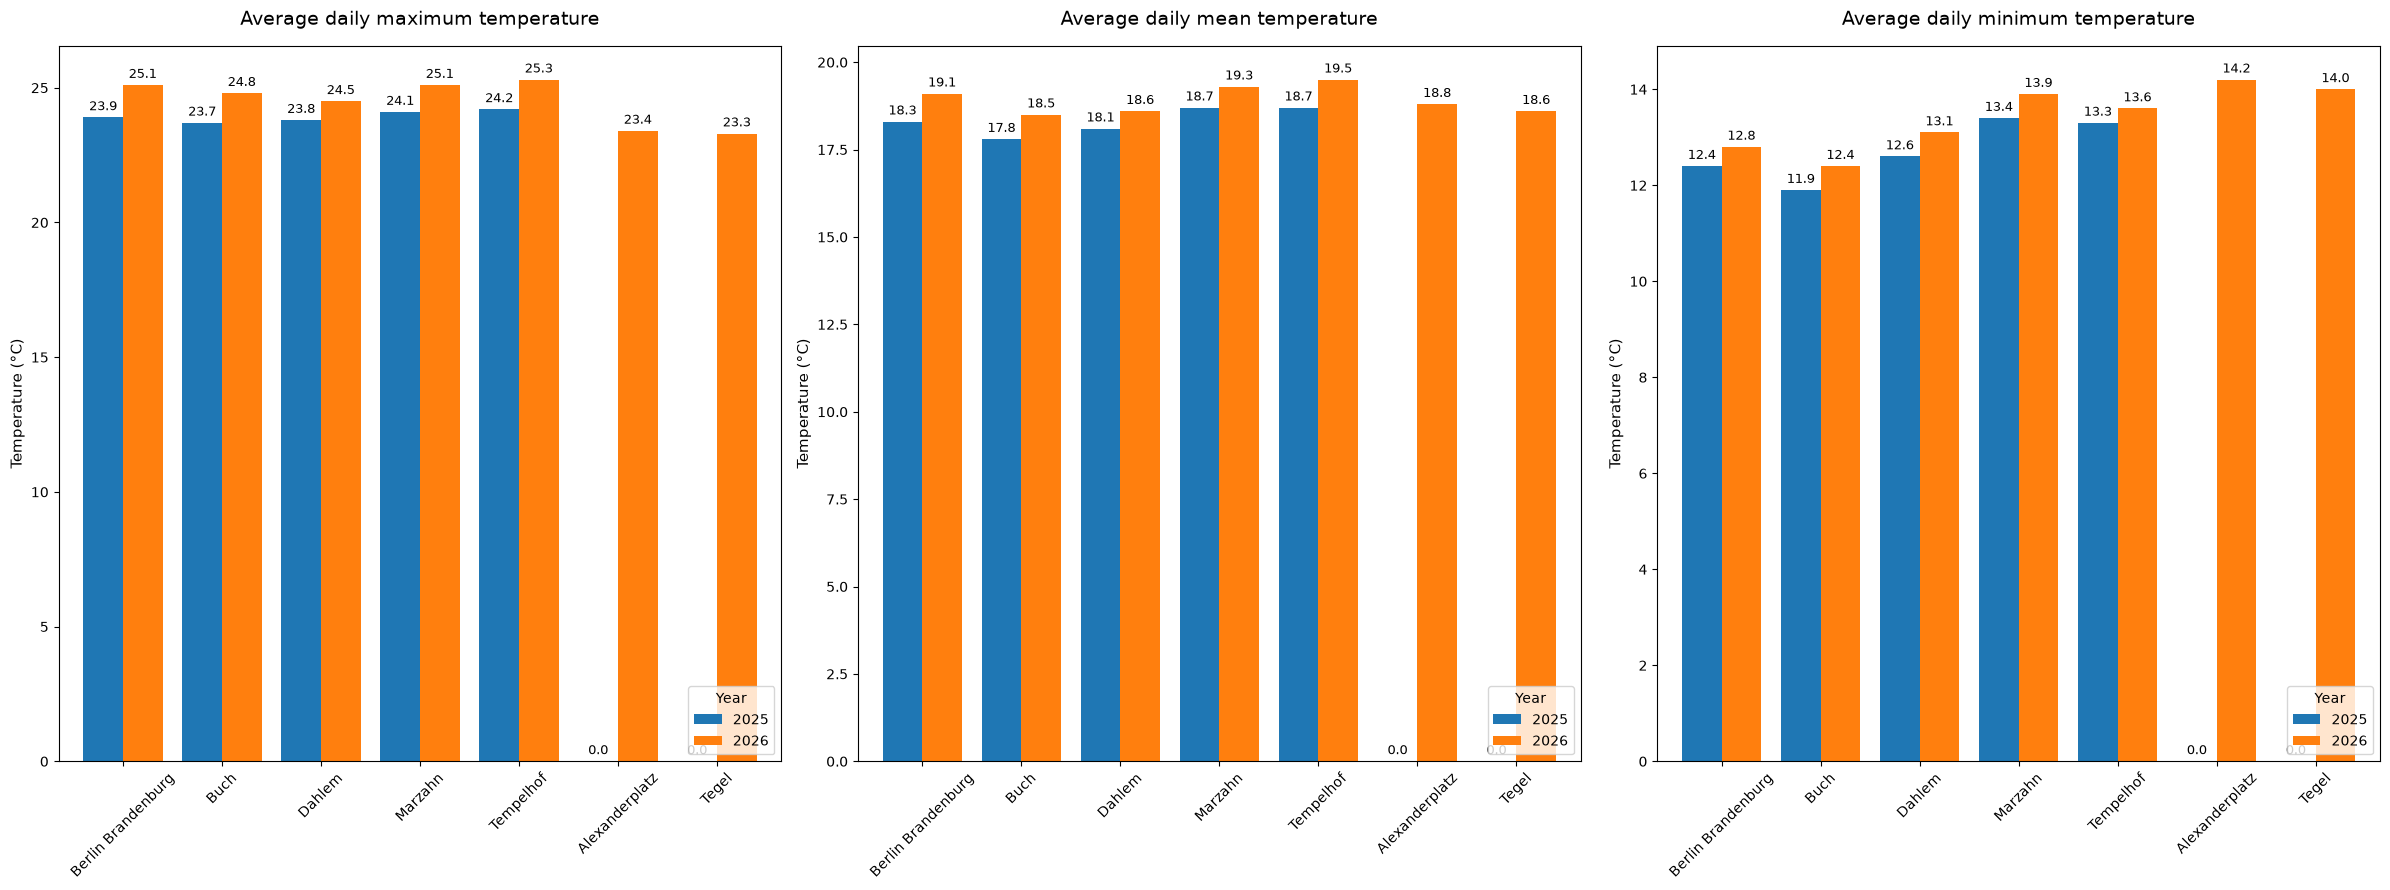

In [49]:
# Create three larger side-by-side charts
fig, axes = plt.subplots(1, 3, figsize=(24, 9))

for ax, (metric, title) in zip(axes, temperature_metrics):

    # Select the metric and arrange stations
    plot_data = temperature_pivot[metric].reindex(station_order)

    # Plot grouped bars
    plot_data.plot(
        kind="bar",
        ax=ax,
        width=0.8
    )

    # Add titles and labels
    ax.set_title(title, fontsize=14, pad=15)
    ax.set_xlabel("")
    ax.set_ylabel("Temperature (°C)", fontsize=11)
    ax.tick_params(axis="x", rotation=45, labelsize=10)
    ax.tick_params(axis="y", labelsize=10)

    # Keep all legends in the bottom-right corner
    ax.legend(title="Year", loc="lower right", fontsize=10)

    # Add value labels above bars
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

Analyzing the tropical nights (nights were the temperature didn't go below 20 C)

In [11]:
# Ensure date is in datetime format
weather_data["date"] = pd.to_datetime(weather_data["date"])

# Filter summer observations
summer_weather = weather_data[
    weather_data["date"].dt.month.isin([6, 7, 8, 9])
].copy()

# Count tropical nights per station, source and year
tropical_nights = (
    summer_weather
    .groupby([
        "station",
        "source",
        summer_weather["date"].dt.year.rename("year")
    ])
    .agg(
        tropical_nights=("tmin", lambda x: (x >= 20).sum()),
        valid_tmin_days=("tmin", "count")
    )
    .reset_index()
)

display(tropical_nights)

,station,source,year,tropical_nights,valid_tmin_days
0,Alexanderplatz,Meteostat,2025,0,122
1,Alexanderplatz,Meteostat,2026,5,122
2,Berlin Brandenburg,DWD,2025,0,122
3,Berlin Brandenburg,DWD,2026,1,122
4,Buch,DWD,2025,0,122
5,Buch,DWD,2026,1,122
6,Dahlem,DWD,2025,0,122
7,Dahlem,DWD,2026,1,122
8,Dahlem,Meteostat,2026,1,122
9,Marzahn,DWD,2025,0,122


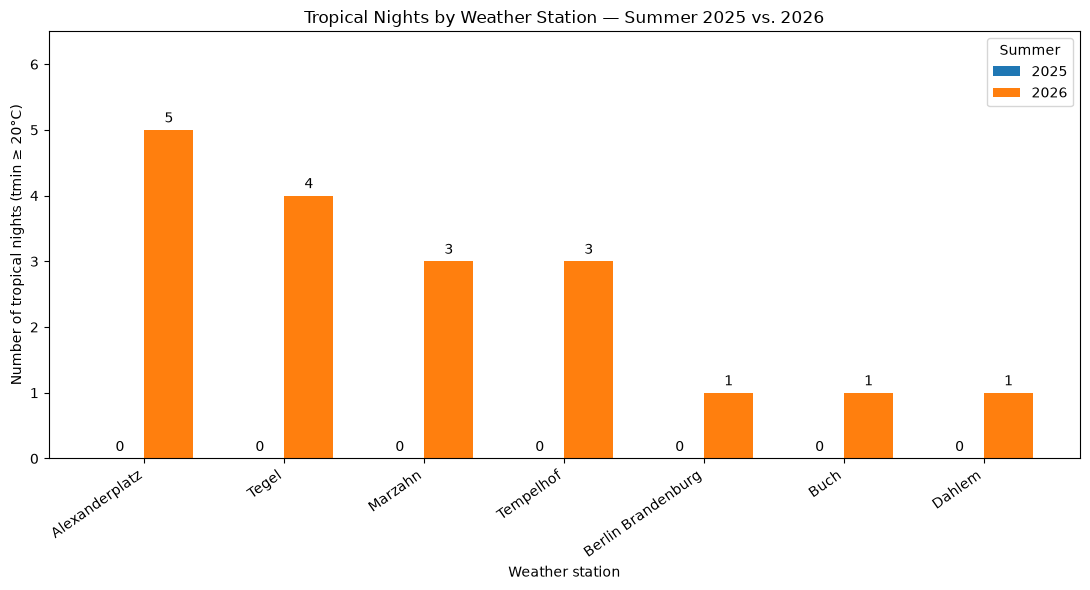

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Select one source per physical station location
preferred_sources = {
    "Berlin Brandenburg": "DWD",
    "Buch": "DWD",
    "Dahlem": "DWD",
    "Marzahn": "DWD",
    "Tempelhof": "DWD",
    "Alexanderplatz": "Meteostat",
    "Tegel": "Meteostat"
}

tropical_selected = tropical_nights[
    tropical_nights.apply(
        lambda row: preferred_sources.get(row["station"]) == row["source"],
        axis=1
    )
].copy()

# Prepare data for plotting
tropical_pivot = tropical_selected.pivot(
    index="station",
    columns="year",
    values="tropical_nights"
)

# Sort stations by 2026 tropical-night count
tropical_pivot = tropical_pivot.sort_values(
    by=2026,
    ascending=False
)

# Create grouped bar chart
x = np.arange(len(tropical_pivot))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars_2025 = ax.bar(
    x - width / 2,
    tropical_pivot[2025],
    width,
    label="2025"
)

bars_2026 = ax.bar(
    x + width / 2,
    tropical_pivot[2026],
    width,
    label="2026"
)

# Add value labels
ax.bar_label(bars_2025, padding=3)
ax.bar_label(bars_2026, padding=3)

ax.set_title("Tropical Nights by Weather Station — Summer 2025 vs. 2026")
ax.set_xlabel("Weather station")
ax.set_ylabel("Number of tropical nights (tmin ≥ 20°C)")
ax.set_xticks(x)
ax.set_xticklabels(tropical_pivot.index, rotation=35, ha="right")
ax.set_ylim(0, tropical_pivot.to_numpy().max() + 1.5)
ax.legend(title="Summer")

plt.tight_layout()
plt.show()

There were no tropical nights in 2025, while in 2026 all stations reported some

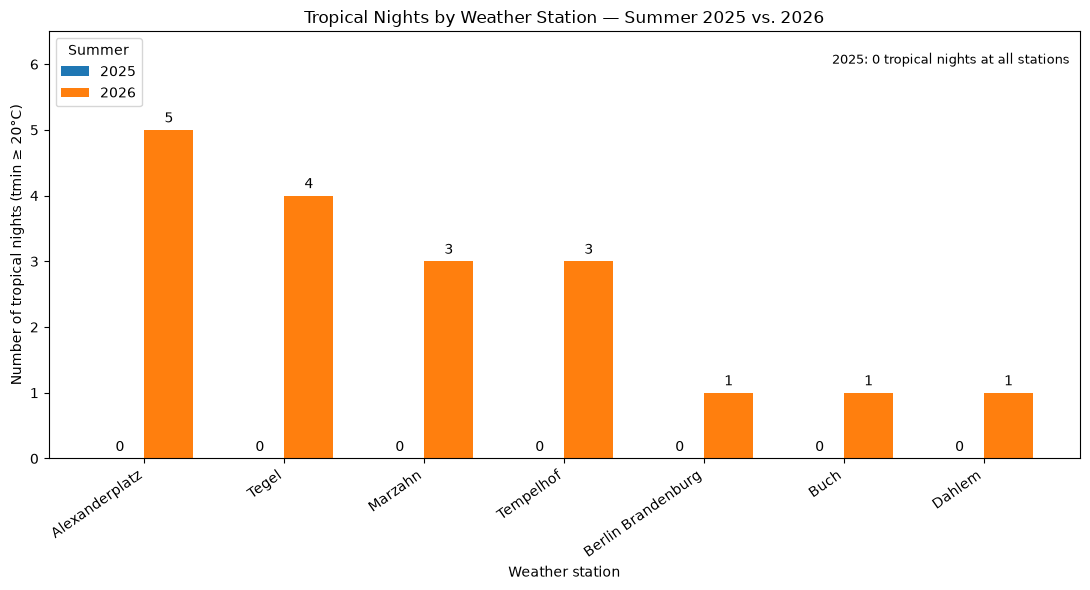

In [19]:
# Create grouped bar chart
x = np.arange(len(tropical_pivot))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars_2025 = ax.bar(
    x - width / 2,
    tropical_pivot[2025],
    width,
    label="2025"
)

bars_2026 = ax.bar(
    x + width / 2,
    tropical_pivot[2026],
    width,
    label="2026"
)

# Add labels for both years
ax.bar_label(bars_2025, labels=["0"] * len(bars_2025), padding=3)
ax.bar_label(bars_2026, padding=3)

ax.set_title("Tropical Nights by Weather Station — Summer 2025 vs. 2026")
ax.set_xlabel("Weather station")
ax.set_ylabel("Number of tropical nights (tmin ≥ 20°C)")
ax.set_xticks(x)
ax.set_xticklabels(tropical_pivot.index, rotation=35, ha="right")
ax.set_ylim(0, tropical_pivot.to_numpy().max() + 1.5)
ax.legend(title="Summer")

# Explain the zero values
ax.text(
    0.99, 0.95,
    "2025: 0 tropical nights at all stations",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9
)

plt.tight_layout()
plt.show()

In [20]:
# Create a month column
summer_weather["month"] = summer_weather["date"].dt.month

# Count tropical nights by station, source, year and month
monthly_tropical = (
    summer_weather
    .groupby([
        "station",
        "source",
        summer_weather["date"].dt.year.rename("year"),
        "month"
    ])
    .agg(
        tropical_nights=("tmin", lambda x: (x >= 20).sum()),
        valid_tmin_days=("tmin", "count")
    )
    .reset_index()
)

# Keep only months with at least one tropical night
display(
    monthly_tropical[
        monthly_tropical["tropical_nights"] > 0
    ].sort_values(["year", "month", "station"])
)

,station,source,year,month,tropical_nights,valid_tmin_days
4,Alexanderplatz,Meteostat,2026,6,3,30
12,Berlin Brandenburg,DWD,2026,6,1,30
20,Buch,DWD,2026,6,1,30
28,Dahlem,DWD,2026,6,1,30
32,Dahlem,Meteostat,2026,6,1,30
40,Marzahn,DWD,2026,6,2,30
44,Marzahn,Meteostat,2026,6,2,30
52,Tegel,Meteostat,2026,6,2,30
60,Tempelhof,DWD,2026,6,2,30
64,Tempelhof,Meteostat,2026,6,2,30


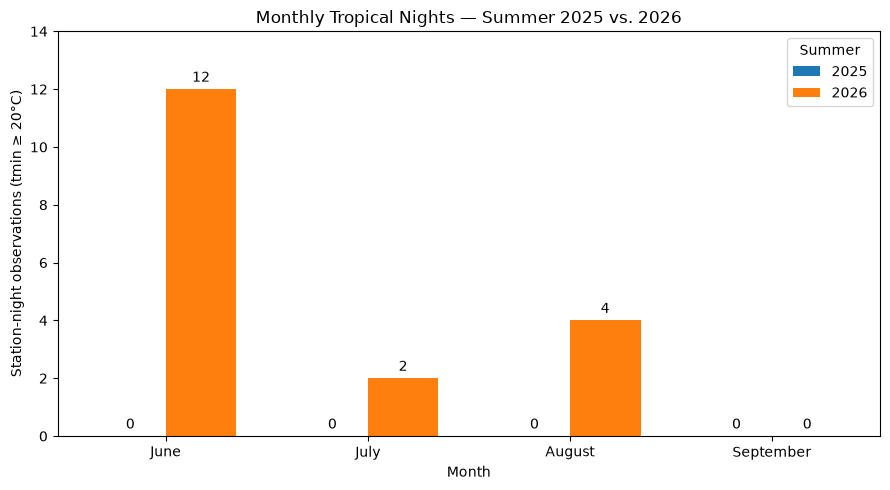

In [21]:
# Keep one source per physical station location
monthly_selected = monthly_tropical[
    monthly_tropical.apply(
        lambda row: preferred_sources.get(row["station"]) == row["source"],
        axis=1
    )
].copy()

# Sum tropical nights across the seven stations per month and year
monthly_totals = (
    monthly_selected
    .groupby(["year", "month"])["tropical_nights"]
    .sum()
    .unstack(fill_value=0)
    .reindex(index=[2025, 2026], columns=[6, 7, 8, 9], fill_value=0)
)

# Create grouped bar chart
months = ["June", "July", "August", "September"]
x = np.arange(len(months))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars_2025 = ax.bar(
    x - width / 2,
    monthly_totals.loc[2025],
    width,
    label="2025"
)

bars_2026 = ax.bar(
    x + width / 2,
    monthly_totals.loc[2026],
    width,
    label="2026"
)

# Label all values, including zero
ax.bar_label(bars_2025, labels=["0"] * 4, padding=3)
ax.bar_label(bars_2026, padding=3)

ax.set_title("Monthly Tropical Nights — Summer 2025 vs. 2026")
ax.set_xlabel("Month")
ax.set_ylabel("Station-night observations (tmin ≥ 20°C)")
ax.set_xticks(x)
ax.set_xticklabels(months)
ax.set_ylim(0, monthly_totals.to_numpy().max() + 2)
ax.legend(title="Summer")

plt.tight_layout()
plt.show()

These are summed station-night observations, not unique nights across Berlin. A single calendar night can contribute to several stations.

In [14]:
# Keep one source per physical station location to show unique tropical nights (instead of showing multiple instances of stations recording the same night)
summer_weather_selected = summer_weather[
    summer_weather.apply(
        lambda row: preferred_sources.get(row["station"]) == row["source"],
        axis=1
    )
].copy()

# Identify tropical-night observations
summer_weather_selected["is_tropical_night"] = (
    summer_weather_selected["tmin"] >= 20
)

# Count unique dates with at least one tropical-night observation
unique_tropical_nights = (
    summer_weather_selected[
        summer_weather_selected["is_tropical_night"]
    ]
    .groupby(summer_weather_selected["date"].dt.year.rename("year"))
    .agg(
        unique_tropical_nights=("date", "nunique")
    )
    .reset_index()
)

display(unique_tropical_nights)

,year,unique_tropical_nights
0,2026,7


In [23]:
# Count distinct physical stations recording a tropical night on each date
tropical_nights_by_date = (
    summer_weather_selected[
        summer_weather_selected["tmin"] >= 20
    ]
    .groupby("date")
    .agg(
        stations_recording_tropical_night=("station", "nunique"),
        stations=("station", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
    .sort_values("date")
)

display(tropical_nights_by_date)

,date,stations_recording_tropical_night,stations
0,2026-06-20,1,Alexanderplatz
1,2026-06-27,2,"Marzahn, Tempelhof"
2,2026-06-28,7,"Alexanderplatz, Berlin Brandenburg, Buch, Dahl..."
3,2026-06-29,2,"Alexanderplatz, Tegel"
4,2026-07-31,2,"Alexanderplatz, Tegel"
5,2026-08-04,2,"Marzahn, Tempelhof"
6,2026-08-05,2,"Alexanderplatz, Tegel"


- June accounts for four of the seven unique dates.
- 28 June was the only date when all seven stations recorded a tropical night.
- The other six dates were recorded at one or two stations.
- July and August each had two unique dates.

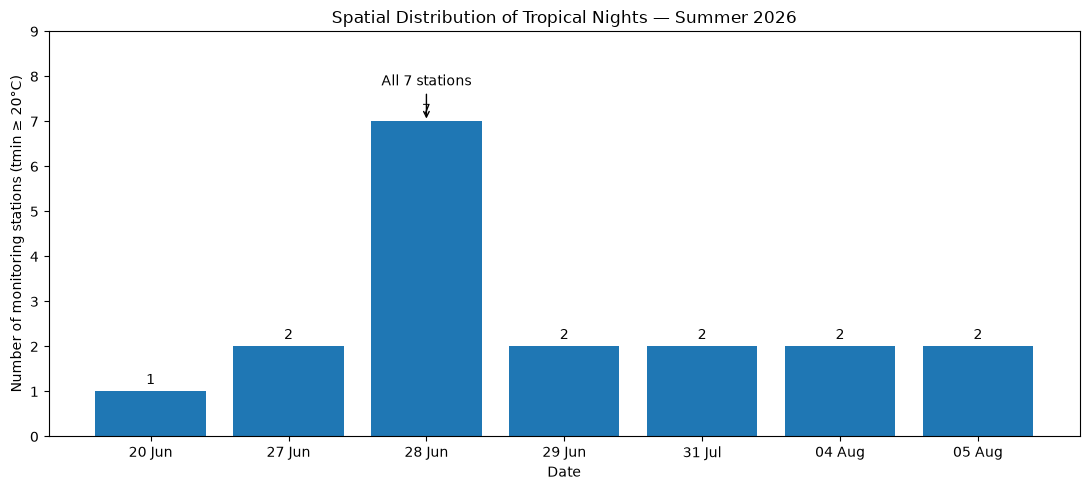

In [24]:
# Create labels for the x-axis
date_labels = tropical_nights_by_date["date"].dt.strftime("%d %b")

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    date_labels,
    tropical_nights_by_date["stations_recording_tropical_night"]
)

# Add value labels
ax.bar_label(bars, padding=3)

# Highlight the full-network event with an annotation
ax.annotate(
    "All 7 stations",
    xy=(2, 7),
    xytext=(2, 7.8),
    ha="center",
    arrowprops=dict(arrowstyle="->")
)

ax.set_title("Spatial Distribution of Tropical Nights — Summer 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Number of monitoring stations (tmin ≥ 20°C)")
ax.set_ylim(0, 9)

plt.tight_layout()
plt.show()

Seven unique tropical-night dates were recorded across the monitoring network during summer 2026. On 28 June, all seven locations registered minimum temperatures of at least 20°C, while the remaining events were observed at one or two stations.

In [25]:
# Count tropical nights per station and year
annual_tropical_nights = (
    summer_weather_selected
    .groupby(["station", summer_weather_selected["date"].dt.year])
    ["is_tropical_night"]
    .sum()
    .reset_index(name="tropical_nights")
    .rename(columns={"date": "year"})
)

# Reshape for easier comparison
annual_tropical_nights_pivot = (
    annual_tropical_nights
    .pivot(index="station", columns="year", values="tropical_nights")
    .fillna(0)
    .astype(int)
)

display(annual_tropical_nights_pivot)

year,2025,2026
station,,
Alexanderplatz,0,5
Berlin Brandenburg,0,1
Buch,0,1
Dahlem,0,1
Marzahn,0,3
Tegel,0,4
Tempelhof,0,3


In [26]:
# Keep only tropical-night observations
monthly_data = summer_weather_selected[
    summer_weather_selected["is_tropical_night"]
].copy()

# Extract year and month
monthly_data["year"] = monthly_data["date"].dt.year
monthly_data["month"] = monthly_data["date"].dt.month

# Aggregate unique dates and station-night observations
monthly_summary = (
    monthly_data
    .groupby(["year", "month"])
    .agg(
        unique_dates=("date", "nunique"),
        station_nights=("station", "count")
    )
)

# Include months with zero tropical nights
all_periods = pd.MultiIndex.from_product(
    [[2025, 2026], [6, 7, 8, 9]],
    names=["year", "month"]
)

monthly_summary = (
    monthly_summary
    .reindex(all_periods, fill_value=0)
    .reset_index()
)

monthly_summary["month"] = monthly_summary["month"].map({
    6: "June",
    7: "July",
    8: "August",
    9: "September"
})

display(monthly_summary)

,year,month,unique_dates,station_nights
0,2025,June,0,0
1,2025,July,0,0
2,2025,August,0,0
3,2025,September,0,0
4,2026,June,4,12
5,2026,July,1,2
6,2026,August,2,4
7,2026,September,0,0


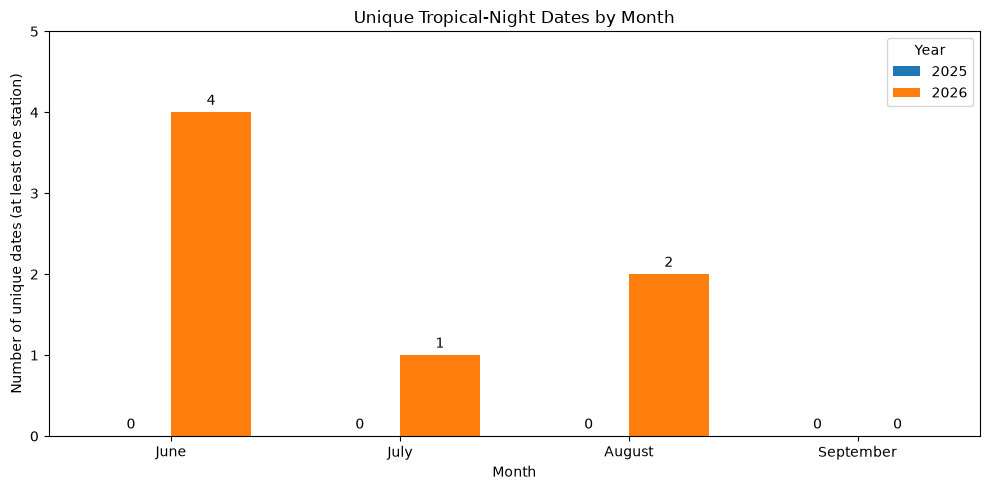

In [27]:
# Prepare chart data
months = ["June", "July", "August", "September"]

data_2025 = (
    monthly_summary[monthly_summary["year"] == 2025]
    ["unique_dates"].to_numpy()
)

data_2026 = (
    monthly_summary[monthly_summary["year"] == 2026]
    ["unique_dates"].to_numpy()
)

x = np.arange(len(months))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

bars_2025 = ax.bar(x - width/2, data_2025, width, label="2025")
bars_2026 = ax.bar(x + width/2, data_2026, width, label="2026")

ax.bar_label(bars_2025, padding=3)
ax.bar_label(bars_2026, padding=3)

ax.set_title("Unique Tropical-Night Dates by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Number of unique dates (at least one station)")
ax.set_xticks(x)
ax.set_xticklabels(months)
ax.set_ylim(0, 5)
ax.legend(title="Year")

plt.tight_layout()
plt.show()

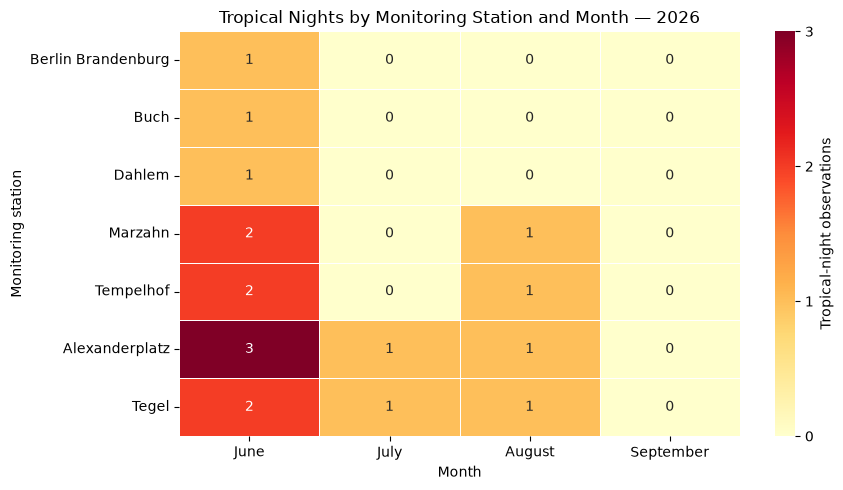

In [ ]:
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.heatmap(
    station_month,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5,
    vmin=0,
    vmax=station_month.to_numpy().max(),
    cbar_kws={
        "label": "Tropical-night observations",
        "ticks": range(0, int(station_month.to_numpy().max()) + 1)
    }
)

plt.title("Tropical Nights by Monitoring Station and Month — 2026")
plt.xlabel("Month")
plt.ylabel("Monitoring station")

plt.tight_layout()
plt.show()

In [30]:
# Get unique dates when at least one station recorded a tropical night
tropical_dates = (
    summer_weather_selected[
        summer_weather_selected["is_tropical_night"]
    ]["date"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

# Identify consecutive-date episodes
episodes = pd.DataFrame({"date": tropical_dates})

episodes["episode"] = (
    episodes["date"].diff().dt.days.ne(1)
).cumsum()

# Summarise each episode
episode_summary = (
    episodes
    .groupby("episode")
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        consecutive_dates=("date", "count")
    )
    .reset_index(drop=True)
)

display(episode_summary)

,start_date,end_date,consecutive_dates
0,2026-06-20,2026-06-20,1
1,2026-06-27,2026-06-29,3
2,2026-07-31,2026-07-31,1
3,2026-08-04,2026-08-05,2


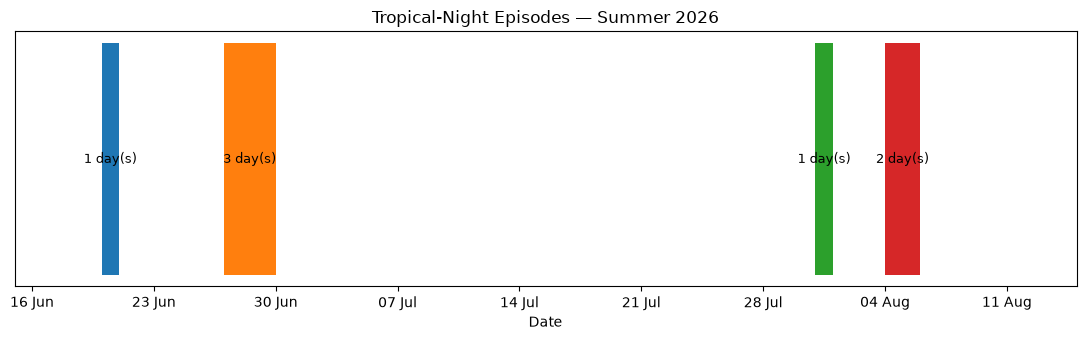

In [31]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(11, 3.5))

for _, row in episode_summary.iterrows():
    ax.barh(
        y=0,
        width=(row["end_date"] - row["start_date"]).days + 1,
        left=mdates.date2num(row["start_date"]),
        height=0.35
    )

    ax.text(
        mdates.date2num(row["start_date"]) +
        ((row["end_date"] - row["start_date"]).days + 1) / 2,
        0,
        f'{row["consecutive_dates"]} day(s)',
        ha="center",
        va="center",
        fontsize=9
    )

ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))

ax.set_title("Tropical-Night Episodes — Summer 2026")
ax.set_xlabel("Date")
ax.set_yticks([])
ax.set_xlim(
    mdates.date2num(pd.Timestamp("2026-06-15")),
    mdates.date2num(pd.Timestamp("2026-08-15"))
)

plt.tight_layout()
plt.show()

Merging Tegel 2025 data into new dataframe

In [8]:
import pandas as pd

tegel_2025 = pd.read_csv("daily_weather_data/tegel_2025.csv")
df_weather_combined_all_updated =  pd.read_csv("merged_complete_datasets/df_weather_combined_all_updated.csv")
tegel_2025.head()

,date,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun
0,2025-01-01 00:00:00,5.3,2.2,7.2,NaN,NaN,NaN,26.6,61.1,1011.2,20
1,2025-01-02 00:00:00,4.5,2.2,7.0,NaN,NaN,NaN,20.0,57.4,1007.1,92
2,2025-01-03 00:00:00,1.5,-0.7,2.7,NaN,NaN,NaN,21.6,55.5,1010.4,7
3,2025-01-04 00:00:00,-0.4,-1.3,0.6,NaN,NaN,NaN,14.4,40.8,1017.3,63
4,2025-01-05 00:00:00,-0.6,-1.6,0.9,NaN,NaN,NaN,14.9,37.0,1005.8,3


In [9]:
# Compare the columns
print("TEGEL 2025:")
print(tegel_2025.columns.tolist())

print("\nEXISTING DATASET:")
print(df_weather_combined_all_updated.columns.tolist())

# Check date coverage
print("\nDate range:")
print(tegel_2025["date"].min(), "to", tegel_2025["date"].max())

# Check for dates already present for Meteostat Tegel
existing_dates = pd.to_datetime(
    df_weather_combined_all_updated.loc[
        (df_weather_combined_all_updated["station"] == "Tegel") &
        (df_weather_combined_all_updated["source"] == "Meteostat"),
        "date"
    ]
)

new_dates = pd.to_datetime(tegel_2025["date"])

print("\nNew records:", len(tegel_2025))
print("Overlapping dates:", new_dates.isin(existing_dates).sum())

TEGEL 2025:
['date', 'tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wdir', 'wspd', 'wpgt', 'pres', 'tsun']

EXISTING DATASET:
['Unnamed: 0', 'station_id', 'date', 'tavg', 'tmin', 'tmax', 'prcp', 'wspd', 'tsun', 'cloud_cover', 'pres_dwd', 'station', 'source', 'pres_meteostat']

Date range:
2025-01-01 00:00:00 to 2025-12-31 00:00:00

New records: 365
Overlapping dates: 0


In [11]:
import numpy as np

# Align Tegel 2025 with the existing dataset structure
tegel_2025_aligned = pd.DataFrame({
    "Unnamed: 0": np.nan,
    "station_id": np.nan,
    "date": tegel_2025["date"],
    "tavg": tegel_2025["tavg"],
    "tmin": tegel_2025["tmin"],
    "tmax": tegel_2025["tmax"],
    "prcp": tegel_2025["prcp"],
    "wspd": tegel_2025["wspd"],
    "tsun": tegel_2025["tsun"],
    "cloud_cover": np.nan,
    "pres_dwd": np.nan,
    "station": "Tegel",
    "source": "Meteostat",
    "pres_meteostat": tegel_2025["pres"]
})

# Check the aligned records
print("New records:", len(tegel_2025_aligned))
print("Missing average temperatures:",
      tegel_2025_aligned["tavg"].isna().sum())
print("Missing maximum temperatures:",
      tegel_2025_aligned["tmax"].isna().sum())

New records: 365
Missing average temperatures: 0
Missing maximum temperatures: 0


In [13]:
# Append Tegel 2025 records
df_weather_combined_all_updated = pd.concat(
    [df_weather_combined_all_updated, tegel_2025_aligned],
    ignore_index=True
)

# Check the updated dataset
print("Total rows:", len(df_weather_combined_all_updated))
print("Tegel records by year:")

df_weather_combined_all_updated[
    (df_weather_combined_all_updated["station"] == "Tegel") &
    (df_weather_combined_all_updated["source"] == "Meteostat")
].groupby(df_weather_combined_all_updated["date"].str[:4]).size()

Total rows: 4995
Tegel records by year:


date
2025    365
2026    303
dtype: int64

In [14]:
# Check for duplicate station-date combinations
duplicates = df_weather_combined_all_updated.duplicated(
    subset=["station", "source", "date"]
)

print("Duplicate station-date records:", duplicates.sum())

# Check missing values in key temperature columns
print("\nMissing temperature values:")
print(df_weather_combined_all_updated[["tavg", "tmax"]].isna().sum())

# Check final dimensions
print("\nDataset shape:", df_weather_combined_all_updated.shape)

# Save the final updated dataset
df_weather_combined_all_updated.to_csv(
    "merged_complete_datasets/df_weather_combined_all_updated.csv",
    index=False
)

Duplicate station-date records: 0

Missing temperature values:
tavg    15
tmax    16
dtype: int64

Dataset shape: (4995, 14)


In [26]:
# Keep one preferred source per physical monitoring location
preferred_sources = {
    "Berlin Brandenburg": "DWD",
    "Buch": "DWD",
    "Dahlem": "DWD",
    "Marzahn": "DWD",
    "Tempelhof": "DWD",
    "Alexanderplatz": "Meteostat",
    "Tegel": "Meteostat"
}

# Filter the summer statistics to the preferred source
weather_selected = weather_summer_stats[
    weather_summer_stats.apply(
        lambda row: preferred_sources.get(row["station"]) == row["source"],
        axis=1
    )
].copy()

display(weather_selected.head())

,station,source,year,mean_tmax,mean_tavg,hot_days,extreme_days,valid_tmax_days
0,Alexanderplatz,Meteostat,2025,22.436885,17.972951,6,1,122
1,Alexanderplatz,Meteostat,2026,23.422951,18.763115,13,3,122
2,Berlin Brandenburg,DWD,2025,23.942623,18.345082,11,1,122
3,Berlin Brandenburg,DWD,2026,25.101639,19.073770,18,5,122
4,Buch,DWD,2025,23.706557,17.786066,9,1,122


In [25]:
# Ensure date is in datetime format
weather_data["date"] = pd.to_datetime(weather_data["date"])

# Filter all sources to summer months (June–September)
summer_weather_all = weather_data[
    weather_data["date"].dt.month.isin([6, 7, 8, 9])
].copy()

# Extract year
summer_weather_all["year"] = summer_weather_all["date"].dt.year

# Calculate summer heat indicators per station, source and year
weather_summer_stats = (
    summer_weather_all
    .groupby(["station", "source", "year"])
    .agg(
        mean_tmax=("tmax", "mean"),
        mean_tavg=("tavg", "mean"),
        hot_days=("tmax", lambda x: (x >= 30).sum()),
        extreme_days=("tmax", lambda x: (x >= 35).sum()),
        valid_tmax_days=("tmax", "count")
    )
    .reset_index()
)

display(weather_summer_stats)

,station,source,year,mean_tmax,mean_tavg,hot_days,extreme_days,valid_tmax_days
0,Alexanderplatz,Meteostat,2025,22.436885,17.972951,6,1,122
1,Alexanderplatz,Meteostat,2026,23.422951,18.763115,13,3,122
2,Berlin Brandenburg,DWD,2025,23.942623,18.345082,11,1,122
3,Berlin Brandenburg,DWD,2026,25.101639,19.073770,18,5,122
4,Buch,DWD,2025,23.706557,17.786066,9,1,122
5,Buch,DWD,2026,24.818852,18.530328,20,4,122
6,Dahlem,DWD,2025,23.810656,18.077049,9,1,122
7,Dahlem,DWD,2026,24.514754,18.649180,15,3,122
8,Dahlem,Meteostat,2026,24.514754,18.649180,15,3,122
9,Marzahn,DWD,2025,24.140984,18.676230,10,2,122


In [27]:
# Keep one preferred source per physical monitoring location
weather_selected = weather_summer_stats[
    weather_summer_stats.apply(
        lambda row: preferred_sources.get(row["station"]) == row["source"],
        axis=1
    )
].copy()

display(weather_selected)

,station,source,year,mean_tmax,mean_tavg,hot_days,extreme_days,valid_tmax_days
0,Alexanderplatz,Meteostat,2025,22.436885,17.972951,6,1,122
1,Alexanderplatz,Meteostat,2026,23.422951,18.763115,13,3,122
2,Berlin Brandenburg,DWD,2025,23.942623,18.345082,11,1,122
3,Berlin Brandenburg,DWD,2026,25.101639,19.073770,18,5,122
4,Buch,DWD,2025,23.706557,17.786066,9,1,122
5,Buch,DWD,2026,24.818852,18.530328,20,4,122
6,Dahlem,DWD,2025,23.810656,18.077049,9,1,122
7,Dahlem,DWD,2026,24.514754,18.649180,15,3,122
9,Marzahn,DWD,2025,24.140984,18.676230,10,2,122
10,Marzahn,DWD,2026,25.061475,19.336066,19,4,122


In [28]:
# Select one source per physical monitoring location
summer_weather_selected = summer_weather_all[
    summer_weather_all.apply(
        lambda row: preferred_sources.get(row["station"]) == row["source"],
        axis=1
    )
].copy()

# Count tropical nights per station and year
summer_weather_selected["is_tropical_night"] = (
    summer_weather_selected["tmin"] >= 20
)

tropical_summary = (
    summer_weather_selected
    .groupby(["station", "year"])
    ["is_tropical_night"]
    .sum()
    .reset_index(name="tropical_nights")
)

# Combine daytime and nighttime indicators
heat_exposure_summary = (
    weather_selected
    .merge(
        tropical_summary,
        on=["station", "year"],
        how="left"
    )
    .sort_values(["year", "station"])
    .reset_index(drop=True)
)

display(heat_exposure_summary.round(2))

,station,source,year,mean_tmax,mean_tavg,hot_days,extreme_days,valid_tmax_days,tropical_nights
0,Alexanderplatz,Meteostat,2025,22.44,17.97,6,1,122,0
1,Berlin Brandenburg,DWD,2025,23.94,18.35,11,1,122,0
2,Buch,DWD,2025,23.71,17.79,9,1,122,0
3,Dahlem,DWD,2025,23.81,18.08,9,1,122,0
4,Marzahn,DWD,2025,24.14,18.68,10,2,122,0
5,Tegel,Meteostat,2025,22.36,17.84,6,1,122,0
6,Tempelhof,DWD,2025,24.20,18.73,11,1,122,0
7,Alexanderplatz,Meteostat,2026,23.42,18.76,13,3,122,5
8,Berlin Brandenburg,DWD,2026,25.10,19.07,18,5,122,1
9,Buch,DWD,2026,24.82,18.53,20,4,122,1


- Tempelhof: highest mean Tmax in both years; 25.29°C in 2026, with 21 hot days and 6 extreme-heat days.
- Buch: largest increase in hot days, from 9 to 20.
- Alexanderplatz: most tropical nights, with 5.
- Tegel: lowest mean Tmax in both years, despite recording 4 tropical nights in 2026.

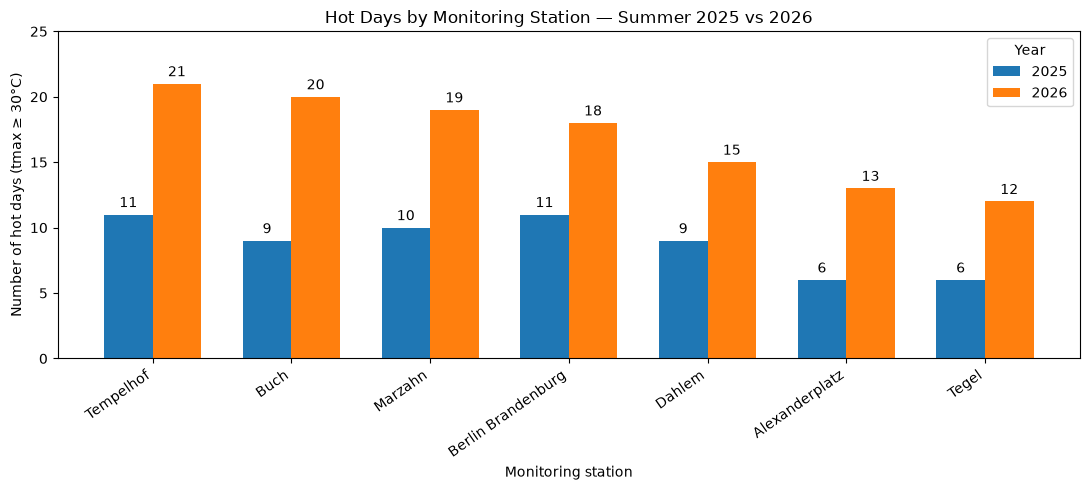

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data
hot_days_pivot = heat_exposure_summary.pivot(
    index="station",
    columns="year",
    values="hot_days"
)

# Sort stations by 2026 hot days
hot_days_pivot = hot_days_pivot.sort_values(
    2026, ascending=False
)

stations = hot_days_pivot.index
x = np.arange(len(stations))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

bars_2025 = ax.bar(
    x - width/2,
    hot_days_pivot[2025],
    width,
    label="2025"
)

bars_2026 = ax.bar(
    x + width/2,
    hot_days_pivot[2026],
    width,
    label="2026"
)

ax.bar_label(bars_2025, padding=3)
ax.bar_label(bars_2026, padding=3)

ax.set_title("Hot Days by Monitoring Station — Summer 2025 vs 2026")
ax.set_xlabel("Monitoring station")
ax.set_ylabel("Number of hot days (tmax ≥ 30°C)")
ax.set_xticks(x)
ax.set_xticklabels(stations, rotation=35, ha="right")
ax.legend(title="Year")

ax.set_ylim(0, 25)

plt.tight_layout()
plt.show()

In [30]:
# Select 2026 observations and the four heat indicators
heat_profile_2026 = heat_exposure_summary[
    heat_exposure_summary["year"] == 2026
][
    [
        "station",
        "mean_tmax",
        "hot_days",
        "extreme_days",
        "tropical_nights"
    ]
].set_index("station")

# Standardise each indicator using z-scores
heat_profile_zscore = (
    heat_profile_2026 - heat_profile_2026.mean()
) / heat_profile_2026.std()

display(heat_profile_zscore.round(2))

,mean_tmax,hot_days,extreme_days,tropical_nights
station,,,,
Alexanderplatz,-1.34,-1.09,-0.87,1.50
Berlin Brandenburg,0.74,0.32,0.87,-0.97
Buch,0.39,0.89,0.00,-0.97
Dahlem,0.01,-0.53,-0.87,-0.97
Marzahn,0.69,0.61,0.00,0.26
Tegel,-1.45,-1.38,-0.87,0.88
Tempelhof,0.97,1.17,1.73,0.26


- Tempelhof stands out for daytime heat: highest mean Tmax, hot-day count and extreme-day count relative to the other stations.
- Alexanderplatz has the highest relative tropical-night count (5 observations), despite below-average daytime indicators.
- Tegel shows a similar contrast: below-average daytime heat indicators but four tropical nights.
- Berlin Brandenburg and Buch have above-average mean Tmax, but only one tropical night each.

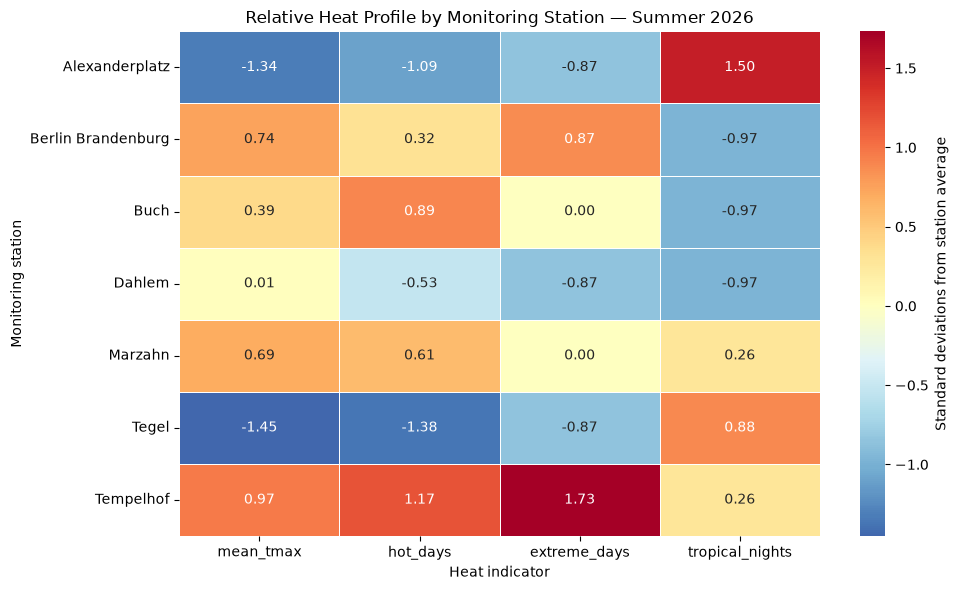

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.heatmap(
    heat_profile_zscore,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={
        "label": "Standard deviations from station average"
    }
)

plt.title("Relative Heat Profile by Monitoring Station — Summer 2026")
plt.xlabel("Heat indicator")
plt.ylabel("Monitoring station")

plt.tight_layout()
plt.show()

- Tempelhof recorded the highest mean daily maximum temperature (25.29°C), the most hot days (21) and the most extreme-heat days (6) in summer 2026. Marzahn also showed above-average values across most daytime heat indicators.

- Alexanderplatz recorded the highest number of tropical nights (5), followed by Tegel (4). Both stations had below-average daytime heat indicators, suggesting that daytime and nighttime heat rankings differed across the monitoring network.

- The results show that heat indicators varied considerably between monitoring locations. No single indicator fully describes the heat profile of a station.

Checking weather data + air quality data

In [33]:
# Load the air-quality dataset
df_air_quality = pd.read_csv(
    "merged_complete_datasets/berlin_air_quality_master_2025_2026.csv"
)

# Check its dimensions
print(df_air_quality.shape)

# Inspect the column names
print(df_air_quality.columns.tolist())

(54305, 8)
['datetime', 'station', 'core', 'component', 'period', 'value', 'station_name', 'station_type']


In [34]:
# Check data types and missing values
print(df_air_quality.info())

# Check available pollutants
print("\nPollutants:")
print(df_air_quality["component"].value_counts())

# Check available station types
print("\nStation types:")
print(df_air_quality["station_type"].value_counts())

# Preview the dataset
display(df_air_quality.head())

<class 'pandas.DataFrame'>
RangeIndex: 54305 entries, 0 to 54304
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datetime      54305 non-null  str    
 1   station       54305 non-null  str    
 2   core          54305 non-null  str    
 3   component     54305 non-null  str    
 4   period        54305 non-null  str    
 5   value         53916 non-null  float64
 6   station_name  54305 non-null  str    
 7   station_type  54305 non-null  str    
dtypes: float64(1), str(7)
memory usage: 6.7 MB
None

Pollutants:
component
no2_24h     9735
no_24h      9735
nox_24h     9735
pm10_24h    7758
pm2_24h     7758
o3_24h      5212
ebc_24h     2455
co_24h      1917
Name: count, dtype: int64

Station types:
station_type
Traffic             21896
Outskirts           17312
Urban background    15097
Name: count, dtype: int64


,datetime,station,core,component,period,value,station_name,station_type
0,2024-12-31 23:00:00+00:00,mc010,ebc,ebc_24h,24h,0.5,Wedding,Urban background
1,2024-12-31 23:00:00+00:00,mc010,no2,no2_24h,24h,9.0,Wedding,Urban background
2,2024-12-31 23:00:00+00:00,mc010,no,no_24h,24h,2.0,Wedding,Urban background
3,2024-12-31 23:00:00+00:00,mc010,nox,nox_24h,24h,12.0,Wedding,Urban background
4,2024-12-31 23:00:00+00:00,mc010,o3,o3_24h,24h,49.0,Wedding,Urban background


In [35]:
# Inspect date format and coverage
print("Sample datetime values:")
print(df_air_quality["datetime"].head())

print("\nDate range:")
print(df_air_quality["datetime"].min())
print(df_air_quality["datetime"].max())

# Inspect measurement periods
print("\nMeasurement periods:")
print(df_air_quality["period"].value_counts())

# Inspect station types and names
print("\nStation types and station counts:")
print(
    df_air_quality.groupby("station_type")["station"]
    .nunique()
)

Sample datetime values:
0    2024-12-31 23:00:00+00:00
1    2024-12-31 23:00:00+00:00
2    2024-12-31 23:00:00+00:00
3    2024-12-31 23:00:00+00:00
4    2024-12-31 23:00:00+00:00
Name: datetime, dtype: str

Date range:
2024-12-31 23:00:00+00:00
2026-10-20 22:00:00+00:00

Measurement periods:
period
24h    54305
Name: count, dtype: int64

Station types and station counts:
station_type
Outskirts           5
Traffic             6
Urban background    4
Name: station, dtype: int64


In [36]:
# Convert air-quality timestamps from UTC to Berlin local time
df_air_quality["datetime"] = pd.to_datetime(
    df_air_quality["datetime"], utc=True
)

df_air_quality["date"] = (
    df_air_quality["datetime"]
    .dt.tz_convert("Europe/Berlin")
    .dt.date
)

# Inspect the converted dates
print("Air-quality date range:")
print(df_air_quality["date"].min(), "to", df_air_quality["date"].max())

# Inspect the weather data structure
print("\nWeather columns:")
print(weather_data.columns.tolist())

print("\nWeather sample:")
display(
    weather_data[["date", "station", "source", "tmax"]].head()
)

Air-quality date range:
2025-01-01 to 2026-10-21

Weather columns:
['Unnamed: 0', 'station_id', 'date', 'tavg', 'tmin', 'tmax', 'prcp', 'wspd', 'tsun', 'cloud_cover', 'pres_dwd', 'station', 'source', 'pres_meteostat']

Weather sample:


,date,station,source,tmax
0,2025-04-09,Berlin Brandenburg,DWD,15.4
1,2025-04-10,Berlin Brandenburg,DWD,14.0
2,2025-04-11,Berlin Brandenburg,DWD,14.8
3,2025-04-12,Berlin Brandenburg,DWD,17.4
4,2025-04-13,Berlin Brandenburg,DWD,22.8


In [37]:
# Select one preferred weather source per physical location
weather_for_air = weather_data[
    weather_data.apply(
        lambda row: preferred_sources.get(row["station"]) == row["source"],
        axis=1
    )
].copy()

# Calculate daily average maximum temperature across selected locations
weather_daily = (
    weather_for_air
    .groupby("date")
    .agg(
        mean_network_tmax=("tmax", "mean"),
        stations_reporting=("tmax", "count")
    )
    .reset_index()
)

# Classify hot days using the network-wide average
weather_daily["is_hot_day"] = (
    weather_daily["mean_network_tmax"] >= 30
)

# Inspect the result
display(weather_daily.head())
print("\nDaily records:", len(weather_daily))
print("\nHot-day classification:")
print(weather_daily["is_hot_day"].value_counts())

,date,mean_network_tmax,stations_reporting,is_hot_day
0,2025-01-01,7.20,2,False
1,2025-01-02,7.00,2,False
2,2025-01-03,2.70,2,False
3,2025-01-04,0.55,2,False
4,2025-01-05,0.90,2,False



Daily records: 668

Hot-day classification:
is_hot_day
False    642
True      26
Name: count, dtype: int64


In [38]:
# Check how many stations report on each date
print("Distribution of reporting stations:")
display(
    weather_daily["stations_reporting"]
    .value_counts()
    .sort_index()
)

# Check station coverage specifically on hot days
print("\nHot days and station coverage:")
display(
    weather_daily[weather_daily["is_hot_day"]]
    [["date", "mean_network_tmax", "stations_reporting"]]
    .sort_values("date")
)

# Check average station coverage on hot vs non-hot days
print("\nAverage reporting stations:")
display(
    weather_daily.groupby("is_hot_day")["stations_reporting"]
    .agg(["count", "mean", "min", "max"])
)

Distribution of reporting stations:


stations_reporting
2    118
6      8
7    542
Name: count, dtype: int64


Hot days and station coverage:


,date,mean_network_tmax,stations_reporting
165,2025-06-15,31.400000,7
172,2025-06-22,33.728571,7
176,2025-06-26,31.714286,7
181,2025-07-01,32.557143,7
182,2025-07-02,37.400000,7
200,2025-07-20,30.528571,7
224,2025-08-13,31.842857,7
225,2025-08-14,33.442857,7
226,2025-08-15,33.757143,7
534,2026-06-19,34.000000,7



Average reporting stations:


,count,mean,min,max
is_hot_day,,,,
False,642,6.068536,2,7
True,26,7.000000,7,7


In [39]:
# Keep dates with at least six weather stations reporting
weather_daily_reliable = weather_daily[
    weather_daily["stations_reporting"] >= 6
].copy()

# Check hot and non-hot day counts
print("Days retained:", len(weather_daily_reliable))

display(
    weather_daily_reliable["is_hot_day"]
    .value_counts()
    .rename(index={True: "Hot", False: "Non-hot"})
)

# Check coverage after filtering
display(
    weather_daily_reliable["stations_reporting"]
    .value_counts()
    .sort_index()
)

Days retained: 550


is_hot_day
Non-hot    524
Hot         26
Name: count, dtype: int64

stations_reporting
6      8
7    542
Name: count, dtype: int64

In [41]:
# Standardise date columns before merging
df_air_quality["date"] = pd.to_datetime(df_air_quality["date"])

weather_daily_reliable["date"] = pd.to_datetime(
    weather_daily_reliable["date"]
)

# Merge weather classification with air-quality measurements
air_quality_heat = df_air_quality.merge(
    weather_daily_reliable[
        ["date", "mean_network_tmax", "is_hot_day"]
    ],
    on="date",
    how="inner"
)

# Check the merged dataset
print("Merged shape:", air_quality_heat.shape)

print("\nDate coverage:")
print(
    air_quality_heat["date"].min(),
    "to",
    air_quality_heat["date"].max()
)

print("\nHot vs non-hot records:")
display(
    air_quality_heat.groupby("is_hot_day")
    .agg(
        records=("value", "size"),
        valid_measurements=("value", "count"),
        unique_dates=("date", "nunique"),
        stations=("station", "nunique")
    )
)

Merged shape: (45149, 11)

Date coverage:
2025-04-09 00:00:00 to 2026-10-10 00:00:00

Hot vs non-hot records:


,records,valid_measurements,unique_dates,stations
is_hot_day,,,,
False,42998,42784,524,15
True,2151,2027,26,15
